# NorthwoodFresh: Did Southeast Revenue Really Drop?

**Client:** Sven Anderson, CFO, NorthwoodFresh
**Question:** Southeast monthly revenue looks lower in the second half of the year. Is that a real shift or just normal month-to-month noise, and how big is it?

**Data note:** This analysis runs on synthetic data generated by `generate_northwoodfresh_data.py` (seed 42). It is a prototype of the method, not a finding about real NorthwoodFresh revenue.

## Section 1: Load and inspect the data

First I load the CSV and check that it has the structure the generation script promised: 48 rows (4 regions x 12 months) and 3 columns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("northwoodfresh_sales.csv")

print("Shape:", df.shape)
print()
print("Column dtypes:")
print(df.dtypes)
print()
print("First rows:")
print(df.head())

assert len(df) == 48, "Expected 48 rows"
print()
print("Row count confirmed: 48")

Shape: (48, 3)

Column dtypes:
region         str
month        int64
revenue    float64
dtype: object

First rows:
      region  month    revenue
0  Northeast      1  532914.57
1  Northeast      2  516405.13
2  Northeast      3  536839.90
3  Northeast      4  559598.78
4  Northeast      5  513912.01

Row count confirmed: 48


The shape is (48, 3), `region` is text, `month` is an integer, and `revenue` is a float. That matches the spec, so I can move on.

## Section 2: Summary statistics by region

For each region I compute the mean, median, standard deviation, and IQR of monthly revenue across the 12 months. Pandas has no built-in IQR aggregation, so I define a small helper (75th percentile minus 25th percentile).

In [2]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

summary = (
    df.groupby("region")["revenue"]
      .agg(mean="mean", median="median", std="std", IQR=iqr)
      .round(2)
)
print(summary.to_string())

                mean     median       std        IQR
region                                              
Midwest    494923.59  491253.53  25492.22   38927.06
Northeast  527694.84  524659.85  19350.27   25196.46
Southeast  417943.34  411262.34  60019.93  120574.07
West       584296.61  577667.87  26461.74   26338.32


Three regions have a standard deviation near 5% of their mean, which is the noise I built in. Southeast stands out: its standard deviation is much larger and its mean sits well below where its first half started. A single mean and standard deviation hide the reason, which is that Southeast is really two different levels glued together. The next section shows that.

## Section 3: Distribution visualizations

Two charts: a histogram of Southeast monthly revenue across all 12 months, and a box plot of revenue by region.

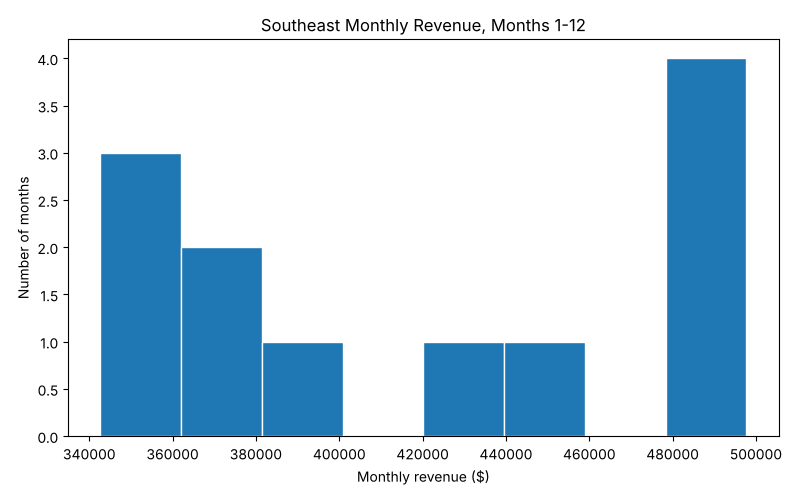

In [3]:
se = df[df["region"] == "Southeast"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(se["revenue"], bins=8, edgecolor="white")
ax.set_title("Southeast Monthly Revenue, Months 1-12")
ax.set_xlabel("Monthly revenue ($)")
ax.set_ylabel("Number of months")
ax.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

The histogram has two clusters: one near $480K (the first six months) and one near $370K (the last six). A single "typical" Southeast value would describe neither period well.

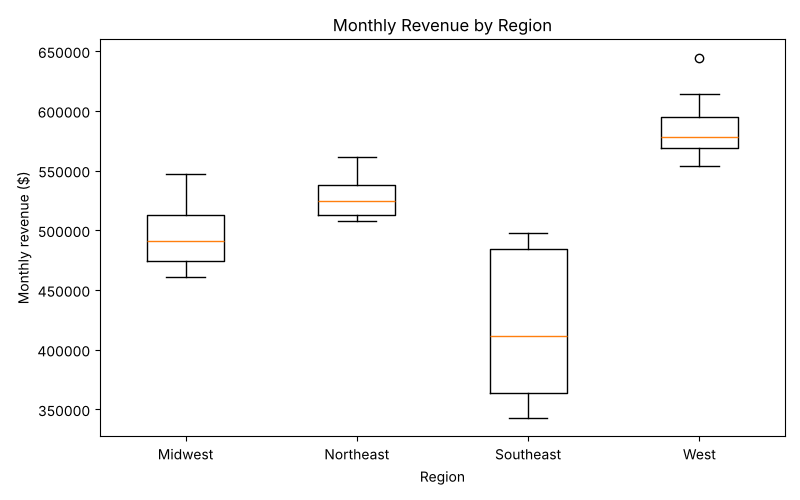

In [4]:
regions = sorted(df["region"].unique())
data = [df.loc[df["region"] == r, "revenue"] for r in regions]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(data, tick_labels=regions)
ax.set_title("Monthly Revenue by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Monthly revenue ($)")
ax.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

Southeast has the widest box and whiskers, and it is the only region whose spread comes from a level shift instead of ordinary noise. The other three regions are compact and stable.

## Section 4: The Southeast question

I split Southeast into the first six months (before) and the last six (after), then report three things together: the effect size, the 95% confidence interval for the difference, and the p-value from a two-sample t-test. The p-value alone would only say "something differs"; the effect size and interval say how much and how precisely we know it.

In [5]:
before = se.loc[se["month"] <= 6, "revenue"]
after = se.loc[se["month"] >= 7, "revenue"]

# Effect size
mean_before, mean_after = before.mean(), after.mean()
diff = mean_before - mean_after
pct_change = (mean_after - mean_before) / mean_before * 100

# 95% CI for the difference in means (manual, 1.96 x SE)
se_diff = np.sqrt(before.var(ddof=1) / len(before) + after.var(ddof=1) / len(after))
ci_low, ci_high = diff - 1.96 * se_diff, diff + 1.96 * se_diff

# Two-sample t-test
t_stat, p_value = stats.ttest_ind(before, after)

print(f"Mean, months 1-6:   ${mean_before:,.2f}")
print(f"Mean, months 7-12:  ${mean_after:,.2f}")
print()
print(f"Effect size (absolute): ${diff:,.2f} lower in months 7-12")
print(f"Effect size (percent):  {pct_change:.1f}% change")
print(f"95% CI for difference:  ${ci_low:,.2f} to ${ci_high:,.2f}")
print(f"CI as % of 'before' mean: {ci_low / mean_before * 100:.1f}% to {ci_high / mean_before * 100:.1f}% drop")
print(f"t-statistic: {t_stat:.3f}")
print(f"p-value:     {p_value:.2e}")
print(f"CI excludes zero: {ci_low > 0}")

Mean, months 1-6:   $472,110.81
Mean, months 7-12:  $363,775.88

Effect size (absolute): $108,334.94 lower in months 7-12
Effect size (percent):  -22.9% change
95% CI for difference:  $84,552.52 to $132,117.36
CI as % of 'before' mean: 17.9% to 28.0% drop
t-statistic: 8.928
p-value:     4.45e-06
CI excludes zero: True


**Reading the result.** Southeast revenue averaged about $108K per month lower in months 7-12, roughly a 23% drop. The 95% confidence interval for that difference does not include zero, and the p-value is tiny, so the drop is very unlikely to be noise. The interval also tells Sven the plausible range of the drop, which matters more for planning than the p-value does.

**Caveats.** The 1.96 multiplier is a normal approximation; with only 6 months per group, a t-based interval would be slightly wider. The test shows the level shifted, not why. It also runs on synthetic data.